scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

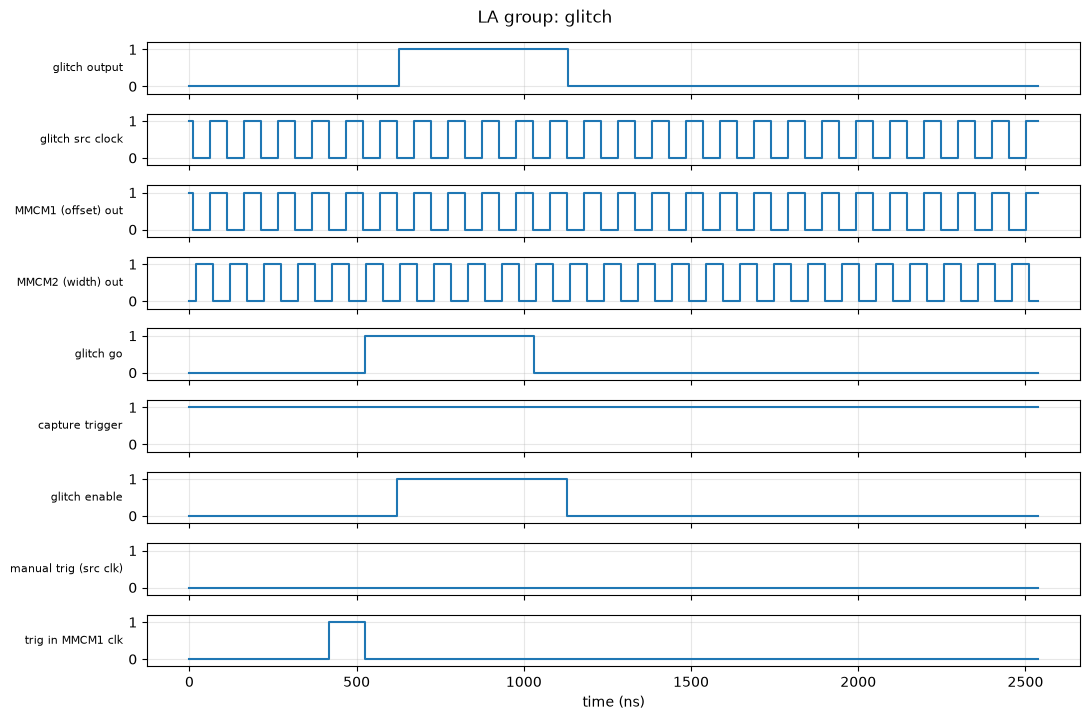

True

In [28]:
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import time

LA_NAMES = {
    "glitch": [
        "glitch output",
        "glitch src clock",
        "MMCM1 (offset) out",
        "MMCM2 (width) out",
        "glitch go",
        "capture trigger",
        "glitch enable",
        "manual trig (src clk)",
        "trig in MMCM1 clk",
    ],
    "CW 20-pin": ["IO1", "IO2", "IO3", "IO4", "HS1", "HS2",
                  "AUX MCX", "TRIG MCX", "ADC sampling clock"],
    "USERIO 20-pin": ["D0", "D1", "D2", "D3", "D4", "D5", "D6", "D7", "CK"],
}

scope = cw.scope()
scope.default_setup()

# ---- glitch setup ----
scope.clock.clkgen_freq = 10e6
scope.glitch.enabled = True
scope.glitch.clk_src = "pll"
# scope.glitch.trigger_src = "manual" # ext_offset is ignored if the trigger is manual 
scope.glitch.output = "enable_only"
scope.glitch.trigger_src = "ext_single"
scope.glitch.ext_offset = 1
scope.glitch.offset = 10
scope.glitch.width = 10
scope.glitch.repeat = 5

# ---- logic analyzer setup ----
scope.LA.enabled = True
scope.LA.clk_source = "pll"
scope.LA.oversampling_factor = 20
scope.LA.downsample = 1
scope.LA.capture_group = "glitch"
scope.trigger.triggers = "tio4"       # use a free pin as trigger input
scope.LA.trigger_source = "capture"   # LA starts on the capture trigger, before the glitch
                                      # Must be one of 'glitch', 'capture', 'glitch_source', 'HS1', '[rising|falling]_userio_d[0-7]', or [rising|falling]_tio[0-3]
scope.LA.capture_depth = 500         # 100 cycles at 4x oversampling is ~400 samples, 500 is too short

try:
    scope.LA.trigger_source = "?"
except Exception as e:
    print(e)

    
scope.LA.arm()
scope.arm()
#scope.glitch.manual_trigger()

# generate the trigger event yourself by driving tio4 from the Husky
scope.io.tio4 = "gpio_high"           # rising edge on tio4 -> trigger
raw = scope.LA.read_capture_data(check_empty=False)

names = LA_NAMES[scope.LA.capture_group]
n_ch = len(names)
sigs = [scope.LA.extract(raw, i) for i in range(n_ch)]

f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
t = np.arange(len(sigs[0])) / f_la * 1e9      # ns

fig, axes = plt.subplots(n_ch, 1, figsize=(11, 1 + 0.7 * n_ch),
                         sharex=True, squeeze=False)
for ax, name, sig in zip(axes[:, 0], names, sigs):
    ax.step(t, sig, where="post")
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    ax.set_yticks([0, 1])
    ax.set_ylim(-0.2, 1.2)
    ax.grid(True, alpha=0.3)
axes[-1, 0].set_xlabel("time (ns)")
fig.suptitle(f"LA group: {scope.LA.capture_group}")
plt.tight_layout()
plt.show()

scope.dis()